# 10. 실험 5 — 확률로 탄소 계산하기 (라벨 없이, 재학습 없음)

**한 줄 요약:** 픽셀을 침엽·활엽·혼효 중 하나로 딱 자르지 않고, 모델이 본 확률대로 탄소를 섞어서 계산한다. 픽셀 탄소 = 침엽 확률×79.25 + 활엽 확률×101.02 + 혼효 확률×92.01.

**쉬운 설명**
- 지금까지: 픽셀마다 "이건 침엽" 하고 잘라서 계수를 곱함 → 혼효는 픽셀 하나의 성질이 아니라 숲 덩어리의 성질이라, 자르는 순간 틀림이 커짐
- 이번: 모델이 "침엽 60%, 활엽 30%, 혼효 10%"라고 봤으면 그 비율대로 섞은 탄소를 줌
- 새 지역의 라벨은 쓰지 않는다. 09에서 저장한 확률(`exp4c_folds`)을 그대로 쓰므로 **RF 재학습 없음**

**주의할 점 (대조군을 넣은 이유)**
확률로 섞으면 모든 지역이 "세 숲을 똑같이 섞은 값(약 90.8)" 쪽으로 끌려간다. 좋아졌을 때 그게 **섞인 숲 정보 덕**인지 **그냥 중간으로 끌린 덕**인지 가르려고, "딱 자른 결과를 같은 만큼 중간으로 끌기만 한 것"(끌기 대조군)을 같이 계산한다.

**비교하는 것**

| 이름 | 방법 | 라벨 |
|---|---|---|
| 딱 자르기 (α=0) | 05·09와 같음 | 없음 |
| 상수 보정 (기준선) | 다른 7곳 평균 오차만큼 뺌 (09와 같음) | 다른 지역 결과만 |
| **확률 섞기 (판정)** | 확률 × 계수 | 없음 |
| 끌기 대조군 (기록만) | 딱 자른 비율을 확률 섞기와 같은 거리만큼 균등 쪽으로 끌기 | 없음 |
| 사전확률 맞춤 (기록만) | balanced 학습 때문에 균등 쪽으로 치우친 확률을 학습 표본 비율로 되돌린 뒤 섞기 | 학습 지역만 |
| 평균 밀도 (기록만) | 다른 7곳의 실제 평균 탄소 밀도 × 면적 | 다른 지역 라벨 |

**순서:** [1] 설정 → [2] 사전 기록(확정 전엔 멈춤) → [3] 함수 → [4] 폴드 읽기·계산(몇 분 [추정]) → [5] 기준선·저장 → [6] 주 결과 → [7] 사전 기록과 대조 → [8] 기록만 → [9] 그림·저장

**끊겼을 때:** `모두 실행` 다시. 원본 수정 없음.


In [1]:
# [1] 설정 — 09 [1]과 같은 경로·지역·계수. RF 재학습 없음
import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive
warnings.filterwarnings('ignore', category=RuntimeWarning)

drive.mount('/content/drive')
OUT      = '/content/drive/MyDrive/forest/outputs'
FOLD_DIR = f'{OUT}/exp4c_folds'                 # 09가 저장한 폴드 파일 (확률 포함)

TRAIN_REGIONS = ['inje', 'hongcheon', 'gangneung', 'pyeongchang',
                 'bonghwa', 'geumsan', 'geochang', 'suncheon']
LAT = {'inje': 38.04, 'hongcheon': 37.75, 'gangneung': 37.71, 'pyeongchang': 37.54,
       'bonghwa': 36.92, 'geumsan': 36.13, 'geochang': 35.71, 'suncheon': 35.01}

C    = {1: 79.25, 2: 101.02, 3: 92.01}            # 확정계수. 구계수 사용 금지
CVEC = np.array([C[1], C[2], C[3]])                # 열 순서 = 침엽·활엽·혼효 (09 proba와 같음)
U    = np.ones(3) / 3                              # 균등 혼합
SEEDS = [16, 17, 18, 19, 20]

for s in SEEDS:
    for r in TRAIN_REGIONS:
        assert os.path.exists(f'{FOLD_DIR}/s{s}_{r}.npz'), f'09 폴드 파일 없음: s{s}_{r}'
assert os.path.exists(f'{OUT}/exp4c_results.npz'), '09 결과 파일 없음'
print('09 폴드 40개·결과 파일 확인 완료')
print(f'균등 혼합 탄소 밀도 = {U @ CVEC:.2f}  (확률로 섞으면 이쪽으로 끌리는 경향)')


Mounted at /content/drive
09 폴드 40개·결과 파일 확인 완료
균등 혼합 탄소 밀도 = 90.76  (확률로 섞으면 이쪽으로 끌리는 경향)


## 실험 5 사전 기록 — 결과를 보기 전에 확정

**읽어 보고 맞으면 [2]의 `CONFIRMED = True`로 바꾼 뒤 실행.**

| 항목 | 내용 (쉬운 말) |
|---|---|
| 설계 | 09의 40폴드 확률을 그대로 사용 (같은 모델·같은 시드). 재학습 없음. 확률로 딱 자른 결과가 09의 α=0과 같은지 폴드마다 확인 (0.01%p) |
| 판정 방법 | **확률 섞기**: 픽셀 탄소 = Σ 확률 × 계수, 지역 합 |
| A. 효과 | 시드마다 \|오차\|가 딱 자르기보다 줄어든 지역 **6/8 이상** AND 평균 개선 **0.1%p 초과** (실험 3·4b·4c와 같은 기준) |
| B. 기준선보다 나음 | 5시드 평균 지역 \|오차\|: 확률 섞기 **<** 상수 보정 |
| 통과 | A가 **5/5 시드** AND B |
| F1 | 판정에서 뺌 (픽셀 예측은 그대로) |
| 사전 예측 [추정] | 지역 \|오차\| 평균 1.1–1.4%, 줄어든 지역 시드당 4–6/8 → **A는 실패할 가능성이 큼**. 좋아질 곳: 인제·평창·금산·순천. 나빠질 곳: 봉화·거창 (실제 탄소 밀도가 균등 혼합 90.8에서 먼 곳). 확률 섞기와 끌기 대조군의 차이는 지역 평균 0.3%p 미만 → 좋아져도 대부분 "중간으로 끌린 덕" |
| 통과하면 | 끌기 대조군과 비교해 섞인 숲 정보 덕인지 확인 → 원리 버전(침엽·활엽 2클래스 + 주변 픽셀 비율로 혼효·탄소) 설계 |
| 실패하면 | 실패 먼저 보고 → 다음 방향 2(학습 지역 수 늘리기)로 |
| 기록만 | 끌기 대조군, 사전확률 맞춤, 평균 밀도, 클래스 비율(실제·딱 자르기·확률), 지역 간 밀도 퍼짐, 면적가중 합산 |

한 번 저장된 `exp5_prereg.json`은 덮어쓰지 않는다.


In [2]:
# [2] 사전 기록 — 확정 전에는 여기서 멈춘다 (정상 정지)
CONFIRMED = True   # ← 위 표를 읽고 맞으면 True로 바꾼다

PREREG = {
    'date': time.strftime('%Y-%m-%d %H:%M'),
    'seen_before_prereg': ('실험 2·3·4a·4b·4c 결과 전체(09 진단 표: 지역별 실제·예측 비율, 혼동표 포함). '
                           '확률 평균·확률 섞기 탄소는 본 적 없음. 사전 예측은 09 비율 표와 "균등 쪽 끌림" 가정으로 손 계산'),
    'purpose': '픽셀을 한 클래스로 자르지 않고 확률대로 탄소를 섞으면 처음 보는 지역 탄소 오차가 줄어드는가 (라벨 없음, 재학습 없음)',
    'design': ('09 exp4c_folds 40폴드의 proba(float16, 열 = 침엽·활엽·혼효) 사용. 행 합으로 다시 나눔. '
               'argmax 탄소 오차가 carb0와 0.01%p 이내인지 폴드마다 assert'),
    'method_judged': '확률 섞기: 지역 탄소 = Σ_픽셀 Σ_k P_k × C_k = n × (확률 평균 · C)',
    'criteria': {
        'A': '시드마다: |오차|가 α=0보다 줄어든 지역 >= 6/8 AND 평균 개선(|e0|-|e_soft|) > 0.1 %p',
        'B': '5시드 평균 지역 |오차|: 확률 섞기 < 상수 보정',
        'pass': 'A 5/5 시드 AND B',
    },
    'baseline_const': '09와 같음: e_r − (같은 시드 나머지 7지역 α=0 오차 평균)',
    'f1': '판정 제외 (픽셀 예측 불변)',
    'prediction': ('[추정] 지역 |오차| 평균 1.1–1.4%, 줄어든 지역 시드당 4–6/8 → A 실패 가능성 큼. '
                   '좋아질 곳 inje·pyeongchang·geumsan·suncheon, 나빠질 곳 bonghwa·geochang. '
                   '확률 섞기와 끌기 대조군의 지역 오차 차이 평균 < 0.3%p'),
    'if_pass': '끌기 대조군과 비교 → 원리 버전(2클래스 픽셀 분류 + 주변 픽셀 비율로 혼효·탄소) 설계',
    'if_fail': '실패 먼저 보고 → 다음 방향 2(학습 지역 수 늘리기, 학습 곡선)',
    'record_only': ['끌기 대조군: 딱 자른 비율 q를 균등 U 쪽으로 λ만큼 끌기, λ = 1 − |확률평균−U| / |q−U| (0–1로 자름)',
                    '사전확률 맞춤: P × prior_train / U 후 행 정규화 (balanced 학습 되돌리기, 학습 지역 라벨만 사용)',
                    '평균 밀도: 같은 시드 나머지 7곳 실제 밀도(t_c/n_test) 단순 평균 × n',
                    '클래스 비율: 실제·딱 자르기·확률 평균', '지역 간 탄소 밀도 퍼짐(표준편차)', '면적가중 합산'],
    'carbon_coeff': C,
    'failure_report': '통과 못 하면 실패라고 먼저 쓴다. 기준을 결과 보고 바꾸지 않는다',
}

PRE = f'{OUT}/exp5_prereg.json'
if os.path.exists(PRE):
    print('이미 저장된 사전 기록을 사용 (덮어쓰지 않음):', PRE)
else:
    assert CONFIRMED, '사전 기록을 읽고 CONFIRMED = True로 바꾼 뒤 다시 실행 (정상 정지)'
    json.dump(PREREG, open(PRE, 'w', encoding='utf-8'), ensure_ascii=False, indent=2)
    print('사전 기록 저장:', PRE)
print(json.dumps(json.load(open(PRE, encoding='utf-8')), ensure_ascii=False, indent=2))


사전 기록 저장: /content/drive/MyDrive/forest/outputs/exp5_prereg.json
{
  "date": "2026-10-03 13:11",
  "seen_before_prereg": "실험 2·3·4a·4b·4c 결과 전체(09 진단 표: 지역별 실제·예측 비율, 혼동표 포함). 확률 평균·확률 섞기 탄소는 본 적 없음. 사전 예측은 09 비율 표와 \"균등 쪽 끌림\" 가정으로 손 계산",
  "purpose": "픽셀을 한 클래스로 자르지 않고 확률대로 탄소를 섞으면 처음 보는 지역 탄소 오차가 줄어드는가 (라벨 없음, 재학습 없음)",
  "design": "09 exp4c_folds 40폴드의 proba(float16, 열 = 침엽·활엽·혼효) 사용. 행 합으로 다시 나눔. argmax 탄소 오차가 carb0와 0.01%p 이내인지 폴드마다 assert",
  "method_judged": "확률 섞기: 지역 탄소 = Σ_픽셀 Σ_k P_k × C_k = n × (확률 평균 · C)",
  "criteria": {
    "A": "시드마다: |오차|가 α=0보다 줄어든 지역 >= 6/8 AND 평균 개선(|e0|-|e_soft|) > 0.1 %p",
    "B": "5시드 평균 지역 |오차|: 확률 섞기 < 상수 보정",
    "pass": "A 5/5 시드 AND B"
  },
  "baseline_const": "09와 같음: e_r − (같은 시드 나머지 7지역 α=0 오차 평균)",
  "f1": "판정 제외 (픽셀 예측 불변)",
  "prediction": "[추정] 지역 |오차| 평균 1.1–1.4%, 줄어든 지역 시드당 4–6/8 → A 실패 가능성 큼. 좋아질 곳 inje·pyeongchang·geumsan·suncheon, 나빠질 곳 bonghwa·geochang. 확률 섞기와 끌기 대조군의 지역 오차 차이 평균 < 0.3%p",
  "if_pass": "끌기 대조군과 비교 → 원리 버전(2클래스

In [3]:
# [3] 함수
def err_pct(carbon, t_c):
    return (carbon - t_c) * 100 / t_c

def carbon_from_props(props, n):
    # 비율(침엽·활엽·혼효) × 픽셀 수 × 계수 (09 [3]과 같음)
    return float(n * (np.asarray(props) @ CVEC))

def reweight_props(P, prior):
    # balanced 학습(학습 쪽 사전확률 = 균등)을 학습 표본 비율로 되돌림. P는 행 합 1
    W = P * (prior / U)
    W /= W.sum(1, keepdims=True)
    return W.mean(0)

def shrink_props(q, s):
    # 끌기 대조군: 딱 자른 비율 q를, 확률 평균 s가 균등에서 떨어진 거리만큼만 남기고 균등 쪽으로 끌기
    dq, ds = np.linalg.norm(q - U), np.linalg.norm(s - U)
    lam = float(np.clip(1 - ds / dq, 0, 1)) if dq > 0 else 0.0
    return (1 - lam) * q + lam * U, lam

# 함수 자체 검산 (가짜 숫자, 1초 미만)
_q = np.array([0.5, 0.3, 0.2])
_P = np.eye(3)[[0] * 5 + [1] * 3 + [2] * 2]
assert np.allclose(_P.mean(0), _q)
assert np.allclose(reweight_props(_P, np.array([0.2, 0.5, 0.3])), _q)      # 확신 100% 확률은 그대로
assert np.allclose(reweight_props(np.tile(_q, (4, 1)), U), _q)               # 균등 사전확률이면 그대로
assert np.allclose(shrink_props(_q, _q)[0], _q) and shrink_props(_q, U)[1] == 1.0
print('함수 정의·검산 완료')


함수 정의·검산 완료


In [4]:
# [4] 폴드 읽기 + 계산 (재학습 없음, 몇 분 [추정])
assert os.path.exists(f'{OUT}/exp5_prereg.json'), '[2] 사전 기록을 먼저 확정 (정상 정지)'
ns, nr = len(SEEDS), len(TRAIN_REGIONS)
E0  = np.full((ns, nr), np.nan); TC = np.full_like(E0, np.nan); NT = np.full_like(E0, np.nan)
NTOT = np.full_like(E0, np.nan); LAM = np.full_like(E0, np.nan); QDIFF = np.full_like(E0, np.nan)
Q   = np.full((ns, nr, 3), np.nan)        # 딱 자르기 비율
TP  = np.full_like(Q, np.nan)             # 실제 비율 (진단용)
PS  = np.full_like(Q, np.nan)             # 확률 평균 (= 확률 섞기 비율)
PW  = np.full_like(Q, np.nan)             # 사전확률 맞춤
PSH = np.full_like(Q, np.nan)             # 끌기 대조군
PRI = np.full_like(Q, np.nan)             # 학습 표본 비율

t0 = time.time()
for i, s in enumerate(SEEDS):
    for j, r in enumerate(TRAIN_REGIONS):
        z = np.load(f'{FOLD_DIR}/s{s}_{r}.npz')
        P = z['proba'].astype('float64')
        n, t_c, e0 = int(z['n_test']), float(z['t_c']), float(z['carb0'])
        assert P.shape == (n, 3), (s, r, P.shape)

        # 검산: 확률로 딱 자른 탄소 = 09 α=0 (float16 반올림 동률 때문에 0.01%p 허용)
        cnt = np.bincount(P.argmax(1), minlength=3)
        e_h = err_pct(float(cnt @ CVEC), t_c)
        assert abs(e_h - e0) < 0.01, f's{s} {r}: argmax 오차 {e_h:.4f} ≠ 09 carb0 {e0:.4f} — 여기서 멈추고 보고'

        P /= P.sum(1, keepdims=True)
        q = np.asarray(z['q'], float)
        E0[i, j], TC[i, j], NT[i, j], NTOT[i, j] = e0, t_c, n, float(z['n_total'])
        Q[i, j], TP[i, j], PRI[i, j] = q, z['true_p'], z['prior_train']
        QDIFF[i, j] = np.abs(cnt / n - q).max()
        PS[i, j] = P.mean(0)
        PW[i, j] = reweight_props(P, PRI[i, j])
        PSH[i, j], LAM[i, j] = shrink_props(q, PS[i, j])
        del P, z
    print(f'시드 {s} 완료 ({time.time() - t0:.0f}초)')

assert not np.isnan(E0).any()
print(f'\n검산 통과: 40폴드 모두 argmax 탄소 = 09 α=0 (0.01%p 이내). 딱 자르기 비율 최대 차이 {QDIFF.max()*100:.4f}%p')


시드 16 완료 (7초)
시드 17 완료 (15초)
시드 18 완료 (21초)
시드 19 완료 (29초)
시드 20 완료 (35초)

검산 통과: 40폴드 모두 argmax 탄소 = 09 α=0 (0.01%p 이내). 딱 자르기 비율 최대 차이 0.0112%p


In [5]:
# [5] 탄소 오차 계산 + 기준선 → exp5_results.npz
def err_from(props):
    return np.array([[err_pct(carbon_from_props(props[i, j], NT[i, j]), TC[i, j]) for j in range(nr)] for i in range(ns)])

E_SOFT = err_from(PS)          # 판정
E_SH   = err_from(PSH)         # 끌기 대조군 (기록)
E_RW   = err_from(PW)          # 사전확률 맞춤 (기록)
assert np.allclose(err_from(Q), E0, atol=1e-6), '비율 → 탄소 계산이 α=0과 다름 — 멈추고 보고'

E_CONST = np.array([[E0[i, j] - np.mean([E0[i, k] for k in range(nr) if k != j]) for j in range(nr)] for i in range(ns)])

DENS = TC / NT                 # 실제 탄소 밀도 (픽셀당)
E_BASE = np.array([[(np.mean([DENS[i, k] for k in range(nr) if k != j]) - DENS[i, j]) * 100 / DENS[i, j]
                    for j in range(nr)] for i in range(ns)])

np.savez(f'{OUT}/exp5_results.npz', e0=E0, e_soft=E_SOFT, e_shrink=E_SH, e_reweight=E_RW, e_const=E_CONST, e_base=E_BASE,
         q=Q, true_p=TP, p_soft=PS, p_reweight=PW, p_shrink=PSH, lam=LAM, prior_train=PRI,
         t_c=TC, n_test=NT, n_total=NTOT, seeds=np.array(SEEDS), regions=np.array(TRAIN_REGIONS))
print('저장: exp5_results.npz')
print(f'(참고) 평균 밀도 기준선 지역 |오차| 평균 {np.abs(E_BASE).mean():.2f}% — 실험 2 보고값 1.84%. '
      '다르면 기준선 정의 차이(판정에 안 씀)')


저장: exp5_results.npz
(참고) 평균 밀도 기준선 지역 |오차| 평균 1.84% — 실험 2 보고값 1.84%. 다르면 기준선 정의 차이(판정에 안 씀)


In [6]:
# [6] 주 결과 — 지역별 (5시드 평균, 부호 포함 %)
tab = pd.DataFrame({
    '딱 자르기 α=0': E0.mean(0),
    '상수 보정': E_CONST.mean(0),
    '확률 섞기': E_SOFT.mean(0),
    '|오차| 줄어든 시드 (확률)': [f'{int((np.abs(E_SOFT[:, j]) < np.abs(E0[:, j])).sum())}/{ns}' for j in range(nr)],
    '(기록) 끌기 대조군': E_SH.mean(0),
    '(기록) 사전확률 맞춤': E_RW.mean(0),
    '(기록) 평균 밀도': E_BASE.mean(0),
}, index=TRAIN_REGIONS)
print(tab.round(3).to_string())
print(f'\n지역 |오차| 평균:  딱 자르기 {np.abs(E0).mean():.2f}%   상수 보정 {np.abs(E_CONST).mean():.2f}%   '
      f'확률 섞기 {np.abs(E_SOFT).mean():.2f}%')
print(f'(기록) 끌기 대조군 {np.abs(E_SH).mean():.2f}%   사전확률 맞춤 {np.abs(E_RW).mean():.2f}%   '
      f'평균 밀도 {np.abs(E_BASE).mean():.2f}%')


             딱 자르기 α=0  상수 보정  확률 섞기 |오차| 줄어든 시드 (확률)  (기록) 끌기 대조군  (기록) 사전확률 맞춤  (기록) 평균 밀도
inje             2.397  1.680  1.689              5/5        1.750         1.207       0.061
hongcheon        0.729 -0.225 -0.078              5/5       -0.006        -0.628      -1.998
gangneung       -0.469 -1.595 -1.134              0/5       -0.487        -1.748      -1.508
pyeongchang      2.382  1.663  1.592              5/5        1.485         1.249      -0.644
bonghwa          1.192  0.304  1.476              0/5        2.198         0.942       3.595
geumsan          2.167  1.418  0.378              5/5        0.367        -0.143      -3.051
geochang         0.377 -0.628  0.422              1/5        1.331        -0.202       2.296
suncheon        -1.364 -2.617 -1.085              5/5       -1.079        -2.179       1.568

지역 |오차| 평균:  딱 자르기 1.38%   상수 보정 1.27%   확률 섞기 0.98%
(기록) 끌기 대조군 1.09%   사전확률 맞춤 1.04%   평균 밀도 1.84%


In [7]:
# [7] 사전 기록과 대조 — 규칙 그대로 계산만. 판정 문장은 사람이 쓴다
nA   = (np.abs(E_SOFT) < np.abs(E0)).sum(1)
gain = (np.abs(E0) - np.abs(E_SOFT)).mean(1)
A_ok = (nA >= 6) & (gain > 0.1)
J = pd.DataFrame({'seed': SEEDS, 'A 줄어든 지역': nA, 'A 평균개선 %p': gain, 'A': A_ok,
                  '(참고) 상수 보정 줄어든 지역': (np.abs(E_CONST) < np.abs(E0)).sum(1),
                  '(참고) 끌기 대조군 줄어든 지역': (np.abs(E_SH) < np.abs(E0)).sum(1)})
print(J.round(3).to_string(index=False))
B_soft, B_const = np.abs(E_SOFT).mean(), np.abs(E_CONST).mean()
B_ok = bool(B_soft < B_const)
PASS = bool(A_ok.all() and B_ok)
print(f'\nA: {A_ok.sum()}/5 시드')
print(f'B: 확률 섞기 {B_soft:.3f}% < 상수 보정 {B_const:.3f}% → {B_ok}')
print(f'통과 = A 5/5 AND B → {"통과" if PASS else "미통과"}')

print(f'\n사전 예측(지역 |오차| 평균 1.1–1.4%): {B_soft:.2f}%,  줄어든 지역 시드별 {"/".join(str(int(v)) for v in nA)} (예측 4–6)')
for r, want in [('inje', '좋아짐'), ('pyeongchang', '좋아짐'), ('geumsan', '좋아짐'), ('suncheon', '좋아짐'),
                ('bonghwa', '나빠짐'), ('geochang', '나빠짐')]:
    j = TRAIN_REGIONS.index(r)
    k = int((np.abs(E_SOFT[:, j]) < np.abs(E0[:, j])).sum())
    print(f'  {r:12s} 예측 {want}: |오차| {np.abs(E0[:, j]).mean():.3f} → {np.abs(E_SOFT[:, j]).mean():.3f}, 줄어든 시드 {k}/5')
d_sh = np.abs(E_SOFT - E_SH).mean(0)
print(f'사전 예측(확률 섞기 vs 끌기 대조군 차이 < 0.3%p): 지역 평균 {d_sh.mean():.3f}%p, 최대 {d_sh.max():.3f}%p ({TRAIN_REGIONS[int(d_sh.argmax())]})')


 seed  A 줄어든 지역  A 평균개선 %p     A  (참고) 상수 보정 줄어든 지역  (참고) 끌기 대조군 줄어든 지역
   16         5      0.385 False                  5                   5
   17         6      0.405  True                  5                   5
   18         5      0.413 False                  5                   5
   19         5      0.395 False                  5                   5
   20         5      0.416 False                  5                   5

A: 1/5 시드
B: 확률 섞기 0.982% < 상수 보정 1.266% → True
통과 = A 5/5 AND B → 미통과

사전 예측(지역 |오차| 평균 1.1–1.4%): 0.98%,  줄어든 지역 시드별 5/6/5/5/5 (예측 4–6)
  inje         예측 좋아짐: |오차| 2.397 → 1.689, 줄어든 시드 5/5
  pyeongchang  예측 좋아짐: |오차| 2.382 → 1.592, 줄어든 시드 5/5
  geumsan      예측 좋아짐: |오차| 2.167 → 0.378, 줄어든 시드 5/5
  suncheon     예측 좋아짐: |오차| 1.364 → 1.085, 줄어든 시드 5/5
  bonghwa      예측 나빠짐: |오차| 1.192 → 1.476, 줄어든 시드 0/5
  geochang     예측 나빠짐: |오차| 0.377 → 0.422, 줄어든 시드 1/5
사전 예측(확률 섞기 vs 끌기 대조군 차이 < 0.3%p): 지역 평균 0.317%p, 최대 0.910%p (geochang)


In [8]:
# [8] 기록만 하는 항목 (판정 없음)
cls = ['침엽', '활엽', '혼효']
rows = []
for j, r in enumerate(TRAIN_REGIONS):
    row = {'지역': r}
    for c in range(3):
        row[f'{cls[c]} 실제'] = TP[:, j, c].mean() * 100
        row[f'{cls[c]} 자르기'] = Q[:, j, c].mean() * 100
        row[f'{cls[c]} 확률'] = PS[:, j, c].mean() * 100
    row['끌기 λ'] = LAM[:, j].mean()
    rows.append(row)
DIAG = pd.DataFrame(rows).set_index('지역')
print('■ 클래스 비율 (5시드 평균, %) — 실제 / 딱 자르기 / 확률 평균')
print(DIAG.round(2).to_string())

print('\n■ 지역 탄소 밀도 (픽셀당, 5시드 평균)')
dens_t = DENS.mean(0)
dens = pd.DataFrame({'실제': dens_t, '딱 자르기': dens_t * (1 + E0.mean(0) / 100),
                     '확률 섞기': dens_t * (1 + E_SOFT.mean(0) / 100), '끌기 대조군': dens_t * (1 + E_SH.mean(0) / 100)},
                    index=TRAIN_REGIONS)
print(dens.round(2).to_string())
print('지역 간 퍼짐(표준편차): ' + '  '.join(f'{c} {dens[c].std(ddof=1):.2f}' for c in dens.columns)
      + f'   (균등 혼합 = {U @ CVEC:.2f})')

def aggregate(E):
    # 지역 오차(%) → 면적가중 합산 오차(%) (09 [10]과 같음)
    dens_p = DENS * (1 + E / 100)
    tot_t = (DENS * NTOT).sum(1)
    return ((dens_p * NTOT).sum(1) - tot_t) * 100 / tot_t
print(f'\n■ 면적가중 합산: 딱 자르기 {aggregate(E0).mean():+.2f}%  상수 {aggregate(E_CONST).mean():+.2f}%  '
      f'확률 섞기 {aggregate(E_SOFT).mean():+.2f}%  끌기 {aggregate(E_SH).mean():+.2f}%  사전확률 맞춤 {aggregate(E_RW).mean():+.2f}%')
print(f'■ 학습 표본 비율(5시드·8폴드 평균, 침엽·활엽·혼효 %): {(PRI.mean((0, 1)) * 100).round(1)}')


■ 클래스 비율 (5시드 평균, %) — 실제 / 딱 자르기 / 확률 평균
             침엽 실제  침엽 자르기  침엽 확률  활엽 실제  활엽 자르기  활엽 확률  혼효 실제  혼효 자르기  혼효 확률  끌기 λ
지역                                                                                 
inje         45.42   34.12  34.09  41.74   49.67  42.57  12.84   16.21  23.33  0.42
hongcheon    37.65   33.39  33.74  49.05   50.43  42.72  13.30   16.18  23.54  0.44
gangneung    40.50   38.88  39.24  48.66   41.62  35.40  10.84   19.50  25.36  0.41
pyeongchang  44.16   33.29  32.74  46.16   54.68  45.97   9.68   12.03  21.29  0.42
bonghwa      60.28   52.65  47.40  32.85   33.59  28.91   6.87   13.76  23.69  0.36
geumsan      32.48   20.64  26.21  51.36   56.83  46.35  16.16   22.54  27.44  0.45
geochang     50.35   52.36  47.40  29.57   36.11  29.53  20.08   11.53  23.07  0.39
suncheon     51.90   47.92  46.89  37.93   18.85  20.13  10.17   33.24  32.98  0.08

■ 지역 탄소 밀도 (픽셀당, 5시드 평균)
                실제  딱 자르기  확률 섞기  끌기 대조군
inje         89.98  92.13  91.50   91.55
hongcheon 

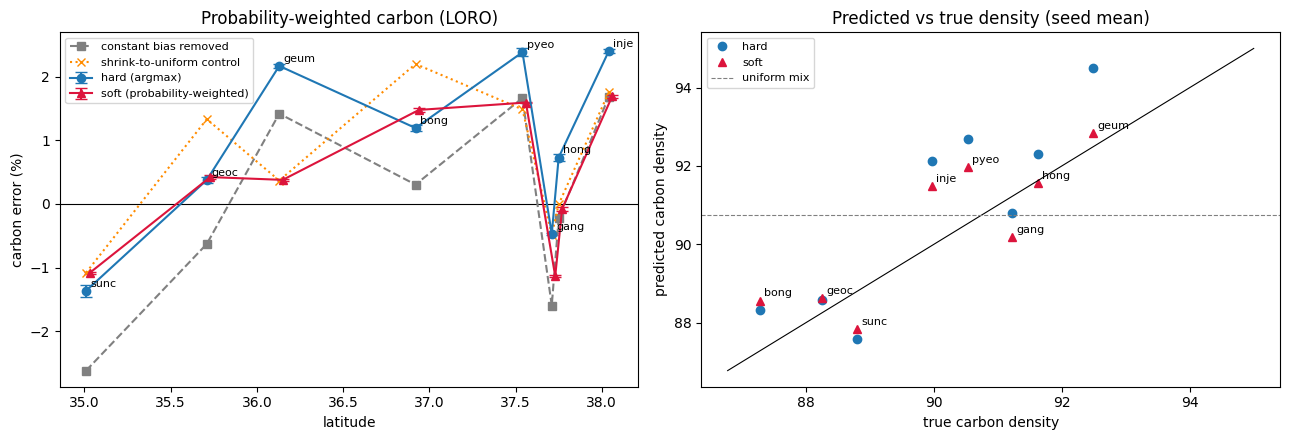

저장: exp5_results.npz, exp5_diag.csv, exp5_by_region.csv, exp5_by_seed.csv, exp5_soft.png
→ [6]–[8] 출력과 그림을 채팅에 붙여넣기


In [9]:
# [9] 그림·저장 (영문 표기)
lat = np.array([LAT[r] for r in TRAIN_REGIONS]); o = np.argsort(lat)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].axhline(0, c='k', lw=.8)
ax[0].errorbar(lat[o], E0.mean(0)[o], yerr=E0.std(0, ddof=1)[o], fmt='o-', capsize=4, label='hard (argmax)')
ax[0].plot(lat[o], E_CONST.mean(0)[o], 's--', c='gray', label='constant bias removed')
ax[0].errorbar(lat[o] + .02, E_SOFT.mean(0)[o], yerr=E_SOFT.std(0, ddof=1)[o], fmt='^-', c='crimson', capsize=4,
               label='soft (probability-weighted)')
ax[0].plot(lat[o], E_SH.mean(0)[o], 'x:', c='darkorange', label='shrink-to-uniform control')
for k in o: ax[0].annotate(TRAIN_REGIONS[k][:4], (lat[k], E0.mean(0)[k]), fontsize=8, xytext=(3, 3), textcoords='offset points')
ax[0].set_xlabel('latitude'); ax[0].set_ylabel('carbon error (%)'); ax[0].legend(fontsize=8)
ax[0].set_title('Probability-weighted carbon (LORO)')

ax[1].plot(dens['실제'], dens['딱 자르기'], 'o', label='hard')
ax[1].plot(dens['실제'], dens['확률 섞기'], '^', c='crimson', label='soft')
lo, hi = dens.values.min() - .5, dens.values.max() + .5
ax[1].plot([lo, hi], [lo, hi], 'k-', lw=.8); ax[1].axhline(U @ CVEC, c='gray', ls='--', lw=.8, label='uniform mix')
for j, r in enumerate(TRAIN_REGIONS): ax[1].annotate(r[:4], (dens['실제'].iloc[j], dens['확률 섞기'].iloc[j]), fontsize=8, xytext=(3, 3), textcoords='offset points')
ax[1].set_xlabel('true carbon density'); ax[1].set_ylabel('predicted carbon density'); ax[1].legend(fontsize=8)
ax[1].set_title('Predicted vs true density (seed mean)')
plt.tight_layout(); plt.savefig(f'{OUT}/exp5_soft.png', dpi=150); plt.show()

DIAG.to_csv(f'{OUT}/exp5_diag.csv')
tab.to_csv(f'{OUT}/exp5_by_region.csv')
J.to_csv(f'{OUT}/exp5_by_seed.csv', index=False)
print('저장: exp5_results.npz, exp5_diag.csv, exp5_by_region.csv, exp5_by_seed.csv, exp5_soft.png')
print('→ [6]–[8] 출력과 그림을 채팅에 붙여넣기')
